# Sepsis Early Warning: does it travel?

**This project is a prototype and is not medical advice.**

Veritas AI International High School Hackathon, Health track. Solo entry by Tanner Barber.

**The question.** Can a sepsis early warning model trained at one hospital travel to another? I train on public intensive care data from hospital A, freeze the model and the alert threshold, and evaluate once on hospital B.

**The user.** An intensive care nurse deciding which patient to look at first.

**How to run this notebook.** `pip install -r requirements.txt`, then run every cell from the top. The first run downloads about 40,000 small public files. The two settings searches take about 35 minutes together, so by default this notebook shows their saved results. Set `RERUN_SEARCHES = True` in the first code cell to repeat them.

All of the working code lives in `src/`. This notebook calls it, so there is one implementation, with tests in `tests/`.

In [1]:
import json, sys, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 200, "display.max_columns", 40)

RERUN_SEARCHES = False   # True repeats both settings searches (about 35 minutes)

## 1. The data

**Dataset:** PhysioNet / Computing in Cardiology Challenge 2019, training sets A and B. Public and de-identified. License: Creative Commons Attribution 4.0. Source: https://physionet.org/content/challenge-2019/1.0.0/

**What one row is:** one hour of one patient's stay in an intensive care unit: 7 vital signs, 26 lab values, age, sex, hours in the unit, and a sepsis label.

**The label.** The challenge defines a sepsis time from two things: clinical suspicion of infection (the earlier of antibiotics being ordered and blood cultures being drawn) and organ damage (a two point rise in the SOFA score). The label switches on 6 hours before that time. So the label depends partly on when the staff acted.

The cell below downloads hospital A only. Hospital B is not downloaded or opened until section 8.

In [2]:
from download import download_hospital
from load import load_hospital

print("new files downloaded for hospital A:", download_hospital("A"))
a = load_hospital("A")
per_patient = a.groupby("pid")["SepsisLabel"].max()
print(f"hospital A: {a.pid.nunique():,} patients, {len(a):,} hourly rows")
print(f"patients who develop sepsis: {int(per_patient.sum()):,} ({100 * per_patient.mean():.1f}%)")
print(f"rows labeled positive: {100 * a.SepsisLabel.mean():.2f}%")
print(f"patients whose label is already on in their first row (late-entry): {int(a.groupby('pid').SepsisLabel.first().sum())}")

new files downloaded for hospital A: 0


hospital A: 20,336 patients, 790,215 hourly rows
patients who develop sepsis: 1,790 (8.8%)
rows labeled positive: 2.17%
patients whose label is already on in their first row (late-entry): 203


In [3]:
# Reading raw rows: the first hours of the first patient. Most cells are empty.
a[["pid", "ICULOS", "HR", "O2Sat", "Temp", "SBP", "MAP", "Resp", "WBC", "Lactate", "Creatinine", "Age", "Gender", "SepsisLabel"]].head(8)

,pid,ICULOS,HR,O2Sat,Temp,SBP,MAP,Resp,WBC,Lactate,Creatinine,Age,Gender,SepsisLabel
0,p000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83.14,0,0
1,p000001,2,97.0,95.0,NaN,98.0,75.33,19.0,NaN,NaN,NaN,83.14,0,0
2,p000001,3,89.0,99.0,NaN,122.0,86.00,22.0,NaN,NaN,NaN,83.14,0,0
3,p000001,4,90.0,95.0,NaN,NaN,NaN,30.0,NaN,NaN,NaN,83.14,0,0
4,p000001,5,103.0,88.5,NaN,122.0,91.33,24.5,NaN,NaN,NaN,83.14,0,0
5,p000001,6,110.0,91.0,NaN,NaN,NaN,22.0,NaN,NaN,NaN,83.14,0,0
6,p000001,7,108.0,92.0,36.11,123.0,77.00,29.0,NaN,NaN,NaN,83.14,0,0
7,p000001,8,106.0,90.5,NaN,93.0,76.33,29.0,NaN,NaN,NaN,83.14,0,0


In [4]:
# How empty is each column at hospital A? (percent of hourly rows with no value)
empty = (100 * a.drop(columns=["pid", "hosp"]).isna().mean()).round(1)
print(empty.to_string())

HR                    7.7
O2Sat                12.0
Temp                 66.2
SBP                  15.2
MAP                  10.2
DBP                  48.1
Resp                  9.8
EtCO2               100.0
BaseExcess           89.6
HCO3                 91.9
FiO2                 85.8
pH                   88.5
PaCO2                91.2
SaO2                 95.0
AST                  98.5
BUN                  91.8
Alkalinephos         98.5
Calcium              95.0
Chloride             91.7
Creatinine           93.4
Bilirubin_direct     99.9
Glucose              87.8
Lactate              96.6
Magnesium            92.2
Phosphate            95.0
Potassium            89.1
Bilirubin_total      98.8
TroponinI            99.9
Hct                  88.2
Hgb                  91.2
PTT                  95.2
WBC                  92.5
Fibrinogen           99.2
Platelets            93.5
Age                   0.0
Gender                0.0
Unit1                48.9
Unit2                48.9
HospAdmTime 

**What I found by reading raw rows.**
- Vital signs are empty in roughly 8% to 15% of hours (temperature 66%). Lab values are empty in 86% to 99.9% of hours. A value being present is itself a signal that something was measured.
- End-tidal CO2 is empty in 100% of hospital A rows, so it is dropped.
- Every sepsis patient has between 6 and 10 positive rows: records stop a few hours after onset.

**Why accuracy is the wrong score here.** About 2% of rows are positive, so a model that never alerts is about 98% accurate and catches nobody. I count per patient instead: caught, missed, and false alarms, reported separately. The exact meanings are in `DEFINITIONS.md`.

## 2. Three piles of patients

Hospital A is cut by patient, never by row: **fit** (the model learns from these), **tune** (used to pick settings), and **dev** (used to set the alert threshold and report hospital A results). If one patient's hours landed in two piles, the model could recognize the patient instead of learning sepsis.

In [5]:
from split import load_piles, make_piles

piles = load_piles()
assert make_piles(a).equals(piles), "the saved piles should be exactly what the seed produces"
ever = a.groupby("pid")["SepsisLabel"].max().rename("sepsis").reset_index()
piles.merge(ever).groupby("pile").agg(patients=("pid", "size"), sepsis_patients=("sepsis", "sum"), sepsis_share=("sepsis", "mean")).round(4)

,patients,sepsis_patients,sepsis_share
pile,,,
dev,4068,358,0.0880
fit,13827,1217,0.0880
tune,2441,215,0.0881


## 3. Inputs, built only from each patient's past

Every input for a patient at hour *t* uses only that patient's rows at hour *t* or earlier. The groups:

| Group | What it holds | First used by |
|---|---|---|
| physiology | latest known value of each vital sign and lab, carried forward | M1 |
| trends | change, mean, lowest and highest of each vital sign over 6 hours | M1 |
| demographics | age and sex | M1 |
| time | hours in the unit, and the gap between hospital and unit admission | M2 |
| measurement | hours since each value was last measured, and counts of labs | M3 |

A lab value appearing in a window is a sign that something was measured. It is not proof a test was ordered at that moment or that a clinician suspected sepsis.

In [6]:
from features import build_features, feature_groups, model_columns

features = build_features(a)
print({group: len(columns) for group, columns in feature_groups().items()})
for name in ["T0", "M1", "M2", "M3"]:
    print(name, "sees", len(json.loads((ROOT / "results" / "frozen.json").read_text())["models"][name]["columns"]), "inputs")
features[["pid", "ICULOS", "last_HR", "change6_HR", "mean6_HR", "hours_since_WBC", "labs_in_last_6h", "hours_in_unit"]].iloc[20:26]

{'physiology': 33, 'trends': 28, 'demographics': 2, 'time': 2, 'measurement': 35, 'scores': 6, 'long_trends': 54, 'measurement_extra': 4}
T0 sees 1 inputs
M1 sees 63 inputs
M2 sees 65 inputs
M3 sees 100 inputs


,pid,ICULOS,last_HR,change6_HR,mean6_HR,hours_since_WBC,labs_in_last_6h,hours_in_unit
20,p000001,21,113.0,7.0,107.600000,4.0,20.0,21
21,p000001,22,98.0,-11.0,105.400000,5.0,20.0,22
22,p000001,23,100.0,-3.0,104.800000,6.0,0.0,23
23,p000001,24,102.0,-2.0,104.400000,7.0,4.0,24
24,p000001,25,108.0,4.0,105.000000,8.0,4.0,25
25,p000001,26,107.0,-2.0,104.666667,9.0,4.0,26


In [7]:
# The no-peeking check, on real patients: cut 200 records short and rebuild.
# The inputs for the hours I kept must come out exactly the same.
some = a[a.pid.isin(a.pid.unique()[:200])]
position = some.groupby("pid", sort=False).cumcount()
kept = position < 12
inputs = sum(feature_groups().values(), [])
full = build_features(some)[kept.to_numpy()].reset_index(drop=True)
cut = build_features(some[kept])
pd.testing.assert_frame_equal(full[inputs], cut[inputs], check_dtype=False)
print("passed: removing the future does not change any input")

passed: removing the future does not change any input


## 4. The comparators on hospital A dev

- **Never alert.** Zero false alarms, zero catches.
- **Modified SIRS**, a bedside screening rule: alert when two or more hold: heart rate over 90; temperature over 38 or under 36 degrees C; breathing rate over 20 or PaCO2 under 32; white cell count over 12 or under 4. "Modified" because the full rule also counts immature white cells (bands), which this data does not record.

In [8]:
from evaluate import evaluate_alerts
from sirs import sirs_alert

features = features.merge(piles, on="pid")
dev = features[features.pile == "dev"].reset_index(drop=True)
sirs_numbers, _ = evaluate_alerts(dev, sirs_alert(dev))
keys = ["sepsis_patients", "caught", "very_early", "missed", "non_sepsis_patients", "false_alarms", "false_alarm_share", "utility"]
pd.Series({k: sirs_numbers[k] for k in keys}, name="Modified SIRS on hospital A dev").round(3).to_frame()

,Modified SIRS on hospital A dev
sepsis_patients,358.000
caught,84.000
very_early,229.000
missed,45.000
non_sepsis_patients,3710.000
false_alarms,2916.000
false_alarm_share,0.786
utility,0.090


SIRS fires on most patients. It rarely misses, and it raises a false alarm on about four of every five patients who never develop sepsis.

## 5. The first model

Gradient boosting builds many small decision trees one after another, each fixing mistakes of the ones before. The version used here (scikit-learn's `HistGradientBoostingClassifier`) accepts empty cells directly.

Six candidate settings were written down first, along with the rule for picking one: judge on the tune pile by the share of sepsis patients alerted at or before onset at the 15% alert budget; among candidates within 1 point of the best, keep the smallest model.

In [9]:
if RERUN_SEARCHES:
    %run scripts/search_settings.py
search = pd.read_csv(ROOT / "results" / "settings_search.csv")
print("tries:", len(search))
search.sort_values("alerted_by_onset", ascending=False).head(8).round(4)

tries: 72


,name,trees,leaves,alerted_by_onset,hourly_auprc,hourly_auroc
9,base,500,31,0.6512,0.1440,0.8326
11,base,600,31,0.6465,0.1437,0.8301
14,base weighted,150,31,0.6465,0.1324,0.8299
15,base weighted,200,31,0.6419,0.1313,0.8284
10,base,550,31,0.6419,0.1432,0.8314
71,slow careful,600,31,0.6372,0.1458,0.8402
8,base,450,31,0.6326,0.1428,0.8318
66,slow careful,350,31,0.6326,0.1498,0.8385


In [10]:
# The first model on hospital A dev. This was my first look at dev.
first = json.loads((ROOT / "results" / "first_model_a_dev_results.json").read_text())
show = ["caught", "very_early", "missed", "false_alarms", "alerted_by_onset_share", "false_alarm_share", "median_hours_of_warning", "utility", "hourly_auroc"]
order = ["Never alert", "Modified SIRS", "T0", "M1", "M2", "M3"]
pd.DataFrame({k: {c: first[k].get(c) for c in show} for k in order}).T.astype(float).round(3)

,caught,very_early,missed,false_alarms,alerted_by_onset_share,false_alarm_share,median_hours_of_warning,utility,hourly_auroc
Never alert,0.0,0.0,358.0,0.0,0.000,0.000,NaN,0.000,NaN
Modified SIRS,84.0,229.0,45.0,2916.0,0.874,0.786,30.0,0.090,NaN
T0,30.0,115.0,213.0,555.0,0.405,0.150,43.0,0.312,0.705
M1,48.0,132.0,178.0,556.0,0.503,0.150,35.5,0.177,0.769
M2,58.0,152.0,148.0,556.0,0.587,0.150,33.5,0.344,0.816
M3,58.0,161.0,139.0,556.0,0.612,0.150,34.0,0.358,0.824


**What the first model showed.**
- Time in the unit alone (T0) scored higher on utility than body signals alone (M1). In this dataset a long stay nearly gives the answer away.
- Most alerts came very early, long before the 12 hour window.
- The settings pick was inside the noise: the tune pile has only 215 sepsis patients.

## 6. The improvement round

Before freezing, I tried to make the model better. The plan and the keep rule were committed first (see `DECISIONS.md`):

- Every choice is made by 3-fold cross-validation over the fit and tune patients together, split by patient. Dev is not used to choose anything.
- A change is kept only if it adds at least 1.5 points of sepsis patients alerted by onset at the 15% budget, and does not lower the utility score by more than 0.01.

In [11]:
if RERUN_SEARCHES:
    %run scripts/improve.py
log = pd.read_csv(ROOT / "results" / "improvement_log.csv")
log.round(4)

,step,what,alerted_by_onset,caught_in_window,utility,hourly_auroc,kept
0,1 baseline,"current inputs, base weighted, 150 trees",0.5943,0.1480,0.3430,0.8149,True
1,2 inputs,added inputs (164 in all),0.6027,0.1676,0.3465,0.8155,False
2,3 settings,"slow careful, 200 trees",0.6110,0.1746,0.3558,0.8214,True
3,4 target,train on the 12 hours before onset,0.6027,0.1487,0.3652,0.8172,False
4,5 smoothing,alert on the average of the last 2 hourly scores,0.6145,0.1725,0.3662,0.8213,False
5,5 smoothing,alert on the average of the last 3 hourly scores,0.6082,0.1662,0.3690,0.8207,False


In [12]:
choice = json.loads((ROOT / "results" / "improvement_choice.json").read_text())
choice

{'extra_inputs': False,
 'settings': 'slow careful',
 'trees': 200,
 'wide_target': False,
 'smooth': 1,
 'cross_validated': {'alerted_by_onset': 0.6110335195530726,
  'caught_in_window': 0.17458100558659218,
  'utility': 0.35584962398848613,
  'hourly_auroc': 0.82138852968709}}

## 7. The final models and the freeze

The cell below retrains T0, M1, M2 and M3 from scratch with the chosen settings on the fit and tune patients and sets each threshold on dev at the 15% alert budget. It writes to a scratch folder, so the frozen models are not touched. The cell after it checks that the retrained thresholds match the frozen file that was committed before hospital B was opened.

All four models share the same settings. The gap from M2 to M3 shows how much the model leans on what was measured and when. That is a care pattern, not a cause.

In [13]:
%run scripts/train_and_score_dev.py --check

choice: {'extra_inputs': False, 'settings': 'slow careful', 'trees': 200, 'wide_target': False, 'smooth': 1, 'cross_validated': {'alerted_by_onset': 0.6110335195530726, 'caught_in_window': 0.17458100558659218, 'utility': 0.35584962398848613, 'hourly_auroc': 0.82138852968709}}


training patients 16268 dev patients 4068


trained: T0


trained: M1


trained: M2


trained: M3


trained: M3 rescaled


                                    sepsis_patients  caught  very_early  missed  false_alarms  false_alarm_share  alerted_by_onset_share  median_hours_of_warning  false_alerts_per_true_alert  alerts_per_1000_patient_days  utility  hourly_auroc  hourly_auprc
T0                                            358.0    30.0       115.0   213.0         555.0              0.150                   0.405                     43.0                        3.828                       106.190    0.312         0.704         0.081
M1                                            358.0    50.0       141.0   167.0         556.0              0.150                   0.534                     30.0                        2.911                       253.129    0.197         0.781         0.085
M2                                            358.0    68.0       149.0   141.0         556.0              0.150                   0.606                     32.0                        2.562                       206.169    0.

In [14]:
frozen = json.loads((ROOT / "results" / "frozen.json").read_text())
candidate = json.loads((ROOT / "data" / "retrain_check" / "a_dev_candidate.json").read_text())
for name, spec in frozen["models"].items():
    same = np.isclose(spec["threshold"], candidate["models"][name]["threshold"], rtol=1e-6)
    print(f"{name:12s} frozen threshold {spec['threshold']:.6f}   retrained here {candidate['models'][name]['threshold']:.6f}   {'match' if same else 'DIFFERENT'}")
print("alert budget:", frozen["budget"], "| settings:", frozen["settings"]["name"], "| trees:", frozen["trees"], "| smoothing hours:", frozen["smooth"])

T0           frozen threshold 0.027093   retrained here 0.027093   match
M1           frozen threshold 0.062288   retrained here 0.062288   match
M2           frozen threshold 0.053485   retrained here 0.053485   match
M3           frozen threshold 0.055630   retrained here 0.055630   match
M3 rescaled  frozen threshold 0.055630   retrained here 0.055630   match
alert budget: 0.15 | settings: slow careful | trees: 200 | smoothing hours: 1


## 8. The one hospital B run

**Disclosure: hospital B is not a blind test.** Before any modeling, hospital B was summarized: patient and row counts, sepsis prevalence, positive-row share, stay length, age and sex mix, sepsis rate by age and by sex, and how empty four columns are. Two label-split facts (how often a lactate value is present, and the unit hour of positive rows) were computed on A and B pooled, and they helped motivate two input groups. No model, input selection, or threshold ever used hospital B. So hospital B is a **site-held-out evaluation set, not a blinded test**.

The real run was done once by `scripts/run_frozen_b.py`, which refuses to run unless the frozen file is committed and refuses to run twice. Its numbers are saved in `results/b_results.json`. The cell below repeats the same scoring with the same frozen models and thresholds and checks that it reproduces those saved numbers.

Two rows use hospital B's unlabeled measurements or scores (never its sepsis labels) and are labeled as such.

In [15]:
from report import evaluate_site, print_table
from rescale import site_norms

print("new files downloaded for hospital B:", download_hospital("B"))
b_raw = load_hospital("B", frozen_run=True)
b_features = build_features(b_raw)
models = {name: joblib.load(ROOT / "models" / f"{name.replace(' ', '_')}.joblib") for name in frozen["models"]}
b_numbers, b_tables, _ = evaluate_site(b_features, frozen, models, site_norms(b_raw))

saved = json.loads((ROOT / "results" / "b_results.json").read_text())
for name in ["M3", "M1", "Modified SIRS"]:
    for key in ["caught", "very_early", "missed", "false_alarms"]:
        assert b_numbers[name][key] == saved[name][key], (name, key)
    assert np.isclose(b_numbers[name]["utility"], saved[name]["utility"], atol=1e-6)
print("reproduced: these numbers match the one frozen run, commit", saved["_run"]["frozen_commit"][:7])
print_table(b_numbers)

new files downloaded for hospital B: 0


reproduced: these numbers match the one frozen run, commit c3fbed6
                                    sepsis_patients  caught  very_early  missed  false_alarms  false_alarm_share  alerted_by_onset_share  median_hours_of_warning  false_alerts_per_true_alert  alerts_per_1000_patient_days  utility  hourly_auroc  hourly_auprc
T0                                           1142.0    79.0       346.0   717.0        2581.0              0.137                   0.372                     45.0                        6.073                        95.434    0.242         0.696         0.048
M1                                           1142.0   103.0       214.0   825.0         994.0              0.053                   0.278                     30.0                        3.136                        94.016    0.091         0.751         0.052
M2                                           1142.0   111.0       391.0   640.0        1452.0              0.077                   0.440                     39

## 9. Results

In [16]:
a_numbers = json.loads((ROOT / "results" / "a_dev_results.json").read_text())

def column(n):
    r = n.get("ranges", {})
    span = lambda key, pct=True: (f" ({100 * r[key][0]:.0f}% to {100 * r[key][1]:.0f}%)" if pct else f" ({r[key][0]:.3f} to {r[key][1]:.3f})") if key in r else ""
    return {
        "Patients": f"{n['patients']:,}",
        "Sepsis patients": f"{n['sepsis_patients']:,}",
        "Official utility score": f"{n['utility']:.3f}" + span("utility", False),
        "Alerted at or before onset": f"{n['caught'] + n['very_early']} ({100 * n['alerted_by_onset_share']:.0f}%)" + span("alerted_by_onset_share"),
        "  caught (within 12 hours before onset)": f"{n['caught']} ({100 * n['caught_share']:.0f}%)",
        "  very early (more than 12 hours before)": f"{n['very_early']}",
        "Missed (no alert by onset)": f"{n['missed']}",
        "False alarms": f"{n['false_alarms']} of {n['non_sepsis_patients']:,} ({100 * n['false_alarm_share']:.1f}%)" + span("false_alarm_share"),
        "False alerts per true alert": f"{n['false_alerts_per_true_alert']:.1f}",
        "Alerts per 1,000 patient-days": f"{n['alerts_per_1000_patient_days']:.0f}",
        "Median hours of warning": f"{n['median_hours_of_warning']:g}",
        "Hourly AUROC": f"{n['hourly_auroc']:.3f}",
    }

print("The full model (M3), threshold frozen on hospital A dev at the 15% alert budget.")
print("Ranges in brackets are 95% ranges from a bootstrap that resamples patients 1,000 times.")
pd.DataFrame({"Hospital A dev": column(a_numbers["M3"]), "Hospital B": column(b_numbers["M3"])})

The full model (M3), threshold frozen on hospital A dev at the 15% alert budget.
Ranges in brackets are 95% ranges from a bootstrap that resamples patients 1,000 times.


,Hospital A dev,Hospital B
Patients,"4,068","20,000"
Sepsis patients,358,"1,142"
Official utility score,0.368 (0.325 to 0.409),0.238 (0.214 to 0.262)
Alerted at or before onset,222 (62%) (57% to 67%),486 (43%) (40% to 46%)
caught (within 12 hours before onset),60 (17%),109 (10%)
very early (more than 12 hours before),162,377
Missed (no alert by onset),136,656
False alarms,"556 of 3,710 (15.0%) (14% to 16%)","1358 of 18,858 (7.2%) (7% to 8%)"
False alerts per true alert,2.5,2.8
"Alerts per 1,000 patient-days",232,115


In [17]:
# Every planned model and both comparators, home and away
rows = {}
for key in ["Never alert", "Modified SIRS", "T0", "M1", "M2", "M3", "M3, same share of patients alerted", "M3 rescaled"]:
    x, y = a_numbers[key], b_numbers[key]
    rows[key] = {
        "utility A dev": round(x["utility"], 3), "utility B": round(y["utility"], 3),
        "alerted by onset A dev": f"{100 * x['alerted_by_onset_share']:.0f}%", "alerted by onset B": f"{100 * y['alerted_by_onset_share']:.0f}%",
        "missed B": y["missed"], "false alarms A dev": f"{100 * x['false_alarm_share']:.1f}%", "false alarms B": f"{100 * y['false_alarm_share']:.1f}%",
    }
pd.DataFrame(rows).T

,utility A dev,utility B,alerted by onset A dev,alerted by onset B,missed B,false alarms A dev,false alarms B
Never alert,0.0,0.0,0%,0%,1142,0.0%,0.0%
Modified SIRS,0.09,-0.014,87%,85%,176,78.6%,67.0%
T0,0.312,0.242,41%,37%,717,15.0%,13.7%
M1,0.197,0.091,53%,28%,825,15.0%,5.3%
M2,0.367,0.247,61%,44%,640,15.0%,7.7%
M3,0.368,0.238,62%,43%,656,15.0%,7.2%
"M3, same share of patients alerted",0.368,0.27,62%,55%,513,15.0%,17.1%
M3 rescaled,0.368,0.246,62%,45%,629,15.0%,8.8%


In [18]:
# Sensitivity at three other alert budgets (thresholds also frozen on hospital A dev)
rows = {}
for key in ["M3 at 5% budget", "M3 at 10% budget", "M3", "M3 at 20% budget"]:
    x, y = a_numbers[key], b_numbers[key]
    rows[key if key != "M3" else "M3 at 15% budget (main)"] = {
        "alerted by onset A dev": f"{100 * x['alerted_by_onset_share']:.0f}%", "false alarms A dev": f"{100 * x['false_alarm_share']:.1f}%",
        "alerted by onset B": f"{100 * y['alerted_by_onset_share']:.0f}%", "false alarms B": f"{100 * y['false_alarm_share']:.1f}%",
    }
pd.DataFrame(rows).T

,alerted by onset A dev,false alarms A dev,alerted by onset B,false alarms B
M3 at 5% budget,45%,5.0%,32%,2.2%
M3 at 10% budget,54%,10.0%,38%,4.4%
M3 at 15% budget (main),62%,15.0%,43%,7.2%
M3 at 20% budget,67%,20.0%,48%,10.7%


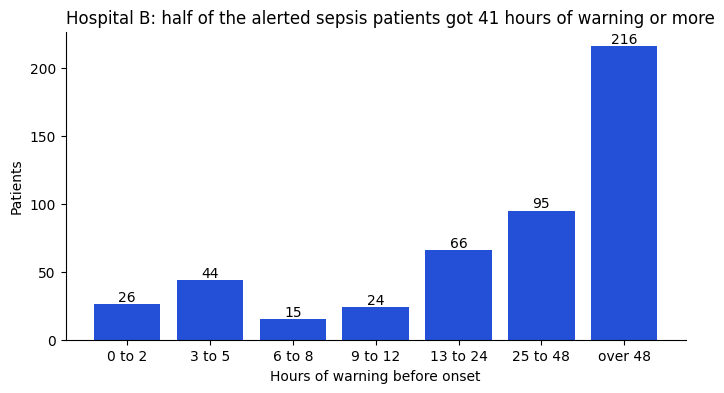

Source: hospital B, 486 sepsis patients with an alert at or before onset. Alerts more than 12 hours early are 'very early', not 'caught'.


In [19]:
# Hours of warning at hospital B, for sepsis patients alerted at or before onset
p = b_tables["M3"]
warned = p[p.outcome.isin(["caught", "very early"])].hours_of_warning
bins = [(0, 2), (3, 5), (6, 8), (9, 12), (13, 24), (25, 48), (49, 10_000)]
labels = ["0 to 2", "3 to 5", "6 to 8", "9 to 12", "13 to 24", "25 to 48", "over 48"]
counts = [int(((warned >= lo) & (warned <= hi)).sum()) for lo, hi in bins]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, counts, color="#2450D8")
ax.bar_label(bars)
ax.set_title(f"Hospital B: half of the alerted sepsis patients got {warned.median():g} hours of warning or more", loc="left")
ax.set_xlabel("Hours of warning before onset"); ax.set_ylabel("Patients")
ax.spines[["top", "right"]].set_visible(False)
plt.show()
print(f"Source: hospital B, {len(warned)} sepsis patients with an alert at or before onset. Alerts more than 12 hours early are 'very early', not 'caught'.")

### Results by age and sex

This is a first check, **not a complete fairness audit**. The data has no race, ethnicity, language or insurance fields, so those groups cannot be checked at all.

In [20]:
def by_group(patients):
    groups = {
        "Female": patients.male == 0, "Male": patients.male == 1,
        "Under 50": patients.age < 50, "50 to 64": (patients.age >= 50) & (patients.age < 65),
        "65 to 79": (patients.age >= 65) & (patients.age < 80), "80 and over": patients.age >= 80,
    }
    out = {}
    for name, mask in groups.items():
        g = patients[mask]; s = g[g.sepsis]; n = g[~g.sepsis]
        in_time = s.outcome.isin(["caught", "very early"]).sum()
        out[name] = {
            "patients": len(g), "sepsis patients": len(s),
            "alerted by onset": f"{in_time} of {len(s)} ({100 * in_time / max(len(s), 1):.0f}%)",
            "missed": int((s.outcome == "missed").sum()),
            "false alarms": f"{int((n.alerts > 0).sum())} of {len(n)} ({100 * (n.alerts > 0).mean():.1f}%)",
        }
    return pd.DataFrame(out).T

print("Hospital B, full model (M3) at the frozen threshold")
by_group(b_tables["M3"])

Hospital B, full model (M3) at the frozen threshold


,patients,sepsis patients,alerted by onset,missed,false alarms
Female,9268,495,210 of 495 (42%),285,545 of 8773 (6.2%)
Male,10732,647,276 of 647 (43%),371,813 of 10085 (8.1%)
Under 50,4818,276,116 of 276 (42%),160,364 of 4542 (8.0%)
50 to 64,6278,351,141 of 351 (40%),210,418 of 5927 (7.1%)
65 to 79,6582,386,183 of 386 (47%),203,462 of 6196 (7.5%)
80 and over,2322,129,46 of 129 (36%),83,114 of 2193 (5.2%)


### Late-entry cases

These are sepsis patients whose label is already on in their first recorded hour, so the record holds no history from before the label. They are reported separately.

In [21]:
pd.DataFrame({
    "Hospital A dev, M3": {**a_numbers["M3"]["late_entry"]}, "Hospital B, M3": {**b_numbers["M3"]["late_entry"]},
    "Hospital B, Modified SIRS": {**b_numbers["Modified SIRS"]["late_entry"]},
})

,"Hospital A dev, M3","Hospital B, M3","Hospital B, Modified SIRS"
sepsis_patients,38,223,223
caught,9,14,150
very_early,0,0,0
missed,29,209,73


## 10. Five failures, read one by one

Chosen by rule from the hospital B run: the first three missed sepsis patients by ID and the first two false alarms by ID, skipping the examples already used in the app. "score/line" is the model's score as a multiple of the alert line, so 1.0 or more means alerting.

In [22]:
%run scripts/show_failures.py B

Failure 1: MISSED  patient p100073  age 50  male  record hours 1 to 27
  label starts hour 19, onset hour 25. First alert: none. Highest score before onset: 0.16 times the alert line.
 hour  score/line    HR  Temp  Resp   MAP   SBP  O2Sat  WBC  Lactate  Creatinine  label
   11        0.05  70.0     .     .  74.0 107.0   95.0    .        .           .      0
   12        0.05  73.0     .     .  83.0 113.0   92.0    .        .           .      0
   13        0.05  80.0  37.2     .  94.0 130.0   98.0    .        .           .      0
   14        0.04  80.0     .     .  98.0 136.0   94.0    .        .           .      0
   15        0.04  77.0     .     .  77.0 113.0   95.0    .        .           .      0
   16        0.06 100.0     .     . 111.0 161.0      .    .        .           .      0
   17        0.08  87.0  37.4     .  83.0 121.0   95.5    .        .           .      0
   18        0.04  72.0     .   4.0 104.0 142.0   95.0    .        .           .      0
   19        0.04  73.0 

Failure 2: MISSED  patient p100088  age 68  male  record hours 1 to 39
  label starts hour 30, onset hour 36. First alert: none. Highest score before onset: 0.37 times the alert line.
 hour  score/line    HR  Temp  Resp  MAP   SBP  O2Sat  WBC  Lactate  Creatinine  label
   22        0.14  82.0     .  14.0 80.0 110.0  100.0    .        .           .      0
   23        0.14  72.0     .  14.0 78.0 110.0  100.0    .        .           .      0
   24        0.14  76.0 37.10  14.0 69.0  92.0  100.0    .        .           .      0
   25        0.14  94.0     .  14.0 65.0  92.0  100.0    .        .           .      0
   26        0.07  81.5     .  14.0 78.5 124.0   99.0    .        .           .      0
   27        0.05  82.0     .  14.0 79.0 126.0  100.0    .        .           .      0
   28        0.06  77.5 36.60  14.0 80.0 130.0  100.0    .        .           .      0
   29        0.06  84.0 36.80  14.0 80.0 122.0  100.0    .        .           .      0
   30        0.06  86.0 36.60  14

Failure 3: MISSED  patient p100111  age 77  male  record hours 1 to 41
  label starts hour 33, onset hour 39. First alert: none. Highest score before onset: 0.34 times the alert line.
 hour  score/line    HR  Temp  Resp   MAP   SBP  O2Sat  WBC  Lactate  Creatinine  label
   25        0.22  99.0  38.5  18.5 104.0 159.0   99.5    .        .           .      0
   26        0.22  98.0  38.4  18.0 102.0 162.0   98.0    .        .           .      0
   27        0.11  99.0     .  18.0 108.0 154.0   96.5    .        .           .      0
   28        0.15 100.0  38.4  18.0 116.0 160.0  100.0    .        .           .      0
   29        0.16  98.0     .  20.0 118.0 162.0  100.0    .        .           .      0
   30        0.15 104.0  38.5  20.0 119.0 163.0   96.0    .        .           .      0
   31        0.14 100.0     .  18.0 120.0 168.0   97.0    .        .           .      0
   32        0.14  95.0     .  18.0 121.0 164.5   99.0    .        .           .      0
   33        0.14  94.0 

Failure 4: FALSE ALARM  patient p100027  age 36  male  record hours 1 to 20
  never developed sepsis. First alert hour 7, 1 separate alert(s). Highest score: 1.06 times the alert line.
 hour  score/line    HR  Temp  Resp   MAP   SBP  O2Sat  WBC  Lactate  Creatinine  label
    1        0.16     .     .     .     .     .      .    .        .           .      0
    2        0.18 125.5     .  17.0  84.0 110.0  100.0    .        .           .      0
    3        0.29 109.0  37.9  21.0  87.0 116.0  100.0    .        .        0.75      0
    4        0.31     .     .     .     .     .      .    .        .           .      0
    5        0.31 113.0     .     .  92.0 124.0   99.0    .        .           .      0
    6        0.28 111.0     .  19.0 105.0 132.0  100.0    .        .           .      0
    7        1.06     .     .     .     .     .      .  5.4     1.49           .      0
    8        0.53 109.0  37.2  17.0  91.0 123.5   99.5    .        .           .      0
    9        0.46 100.0

Failure 5: FALSE ALARM  patient p100046  age 62  male  record hours 1 to 59
  never developed sepsis. First alert hour 58, 1 separate alert(s). Highest score: 1.31 times the alert line.
 hour  score/line    HR  Temp  Resp  MAP   SBP  O2Sat  WBC  Lactate  Creatinine  label
   50        0.28  93.0 37.70     . 62.0  89.0   99.0    .        .        1.73      0
   51        0.36 102.0 37.60  23.0 66.0  96.0   97.0    .        .           .      0
   52        0.33 103.0 37.60  20.0 79.0 129.0   95.0    .        .           .      0
   53        0.42 105.0 37.60  21.0 82.5 132.0   97.5    .        .           .      0
   54        0.52 111.5 37.75  20.0 83.5 141.5   98.5    .        .           .      0
   55        0.60 100.0 37.70  19.0 86.0 151.0   98.0    .        .           .      0
   56        0.54  97.0 37.80  17.0 80.0 140.0   98.0    .        .           .      0
   57        0.93 103.0 38.00     . 85.0 152.0   96.0    .        .           .      0
   58        1.31 103.0 37.90  

## 11. What this does and does not show

- **Site-held-out, not blind.** See the disclosure in section 8. A truly unseen hospital is future work.
- **Not comparable to the challenge leaderboard.** The challenge scored teams on hidden patients, including a third hospital that was never released. My test is hospital A to hospital B on public data.
- **Time in the unit explains a lot.** Compare T0 with M1 above. Part of what looks like skill is the shape of this dataset.
- **Very early alerts are not the same as catches.** I report them separately.
- **The label depends on staff behavior.** It is built partly from when antibiotics were ordered and cultures drawn.
- **Scores are model scores, not probabilities.** Calibration was not checked.
- **Hospital A dev numbers are calibration numbers.** The alert line was set on those patients, so the 15.0% false alarm share at hospital A dev is true by construction, not a measured result.
- **Retrospective only.** Nothing here was tested with a real nurse or on live data.

Would this be safe to use? **No.** It would need a prospective test at the hospital that would use it, a check that staff act on its alerts, calibration, and a far wider fairness audit.

## Credits

- Data and challenge: Reyna MA, Josef CS, Jeter R, et al. "Early Prediction of Sepsis from Clinical Data: the PhysioNet/Computing in Cardiology Challenge 2019." Critical Care Medicine, 2020. Data license CC BY 4.0.
- Scoring: the challenge organizers' `evaluate_sepsis_score.py`, unchanged, BSD 2-Clause license, in `third_party/`.
- Libraries: pandas, NumPy, scikit-learn, Matplotlib, Plotly, Gradio, Jupyter.
- AI tools: Claude Code wrote most of the code from Tanner's instructions and ran the literature checks. ChatGPT (Codex) gave an outside review after the freeze. Tanner chose the question, the user, the alert budget, and the definitions, adopted the prediction before any model was trained, decided to improve the model before freezing, and read the failures.

This project is a prototype and is not medical advice.

## 12. After the hospital B run: version 2 (after-the-fact)

**Everything in this section was run after hospital B had been scored.** Version 1 above (utility 0.368 at hospital A dev and 0.238 at hospital B, with 109 of 1,142 timely alerts there) stays the result of record, and nothing below replaces it. Version 2 asks a different question: what is the best model that can be built once both hospitals have been seen?

Three things to keep in mind while reading these tables:
- **None of this is a test of travel.** Hospital B had already been seen, and several of these models train on it.
- **It is a different test from version 1.** Most rows use a 25% false alarm cap where version 1 used a 15% budget, so these scores are not a like for like improvement on version 1.
- **Each plan was written down before its run**, with a guess, in the "Version 2" section of `DECISIONS.md`. The cells below train nothing. They read the saved result files `results/after_the_fact_v2_*.csv`, which the `scripts/v2_*.py` scripts wrote.

In [23]:
pd.set_option("display.max_colwidth", 80)

def v2_table(file, labels, utility_decimals=3):
    # Read one saved version 2 result file and lay it out the same way every time.
    t = pd.read_csv(ROOT / "results" / file)
    out = t[labels].copy()
    out["utility"] = t.utility.round(utility_decimals)
    out["timely"] = [f"{c:,} of {s:,}" for c, s in zip(t.caught, t.sepsis_patients)]
    out["alerted by onset"] = [f"{100 * x:.1f}%" for x in t.alerted_by_onset_share]
    out["missed"] = t.missed
    out["false alarms"] = [f"{f:,} of {n:,} ({100 * r:.1f}%)" for f, n, r in zip(t.false_alarms, t.non_sepsis_patients, t.false_alarm_share)]
    return out

### 12.1 One model trained on both hospitals

Trained on hospital A's fit and tune patients plus all of hospital B, and scored with nested cross-validation: no patient is scored by a model or an alert line that saw them. The 25% cap is applied at each hospital separately. A hospital A only model on the same folds is the baseline.

In [24]:
both = v2_table("after_the_fact_v2_both_hospitals.csv", ["model", "cutoff", "cap", "scored_on"])
both[(both.cutoff == "per hospital") & (both.cap == 0.25)].drop(columns=["cutoff", "cap"]).reset_index(drop=True)

,model,scored_on,utility,timely,alerted by onset,missed,false alarms
0,A only,hospital A,0.399,"304 of 1,432",72.7%,391,"3,816 of 14,836 (25.7%)"
1,both hospitals,hospital A,0.402,"295 of 1,432",72.1%,399,"3,766 of 14,836 (25.4%)"
2,both hospitals,hospital B,0.406,"364 of 1,142",80.7%,220,"4,755 of 18,858 (25.2%)"
3,both hospitals,both together,0.403,"659 of 2,574",76.0%,619,"8,521 of 33,694 (25.3%)"


**What it means.** With hospital B's labeled patients in training and its own alert line, hospital B reaches utility 0.406 with 220 of 1,142 sepsis patients missed. This model has seen both hospitals, so it cannot claim to travel. At hospital A the extra data did not meet the keep rule: 0.402 against 0.399 for the hospital A only model, with no more patients alerted by onset.

For comparison only, the same model with one shared cutoff for both hospitals:

In [25]:
both[(both.cutoff == "shared") & (both.cap == 0.25)].drop(columns=["cutoff", "cap"]).reset_index(drop=True)

,model,scored_on,utility,timely,alerted by onset,missed,false alarms
0,both hospitals,hospital A,0.416,"327 of 1,432",79.5%,293,"4,887 of 14,836 (32.9%)"
1,both hospitals,hospital B,0.399,"339 of 1,142",75.5%,280,"3,685 of 18,858 (19.5%)"
2,both hospitals,both together,0.409,"666 of 2,574",77.7%,573,"8,572 of 33,694 (25.4%)"


One shared alert line breaks the 25% cap at hospital A (32.9% false alarms) and leaves hospital B well under it (19.5%). Each hospital needs its own alert line, even inside one model.

### 12.2 The frozen version 1 model with hospital B's own alert line

The model is not retrained. Its cutoff is set on hospital A dev at the 25% cap. At hospital B the first 2,000 patients by ID are a burn-in group: using their scores only, never their sepsis labels, the cutoff is moved until it alerts on the same share of all patients as at hospital A dev. The other 18,000 patients are then scored once.

In [26]:
v2_table("after_the_fact_v2_alert_line.csv", ["alert_line", "scored_on"])

,alert_line,scored_on,utility,timely,alerted by onset,missed,false alarms
0,hospital A cutoff at the 25% cap,hospital A dev (calibration set),0.420,78 of 358,74.3%,92,"927 of 3,710 (25.0%)"
1,"hospital A cutoff, unchanged","hospital B, the 18,000 after burn-in",0.265,"142 of 1,024",52.7%,484,"2,585 of 16,976 (15.2%)"
2,"hospital B's own line from burn-in, no labels","hospital B, the 18,000 after burn-in",0.271,"171 of 1,024",62.6%,383,"4,747 of 16,976 (28.0%)"
3,"hospital A cutoff, unchanged","hospital B, all 20,000",0.267,"159 of 1,142",53.4%,532,"2,867 of 18,858 (15.2%)"


**What it means.** On the same 18,000 patients, hospital B's own line misses 383 of 1,024 sepsis patients where hospital A's line misses 484. But false alarms go from 15.2% to 28.0%, and utility barely moves (0.265 to 0.271). Moving the line trades alarms for catches. It does not make the model better at ranking hospital B's patients.

### 12.3 Run backwards: train at hospital B, test at hospital A

The mirror of version 1. Hospital B is cut by patient, 80% to train and 20% to set the cutoff. Then all of hospital A is scored once.

In [27]:
v2_table("after_the_fact_v2_reverse.csv", ["budget", "scored_on"])

,budget,scored_on,utility,timely,alerted by onset,missed,false alarms
0,0.15,"hospital B, the 20% used to set the cutoff (calibration set)",0.380,58 of 228,70.2%,68,"563 of 3,772 (14.9%)"
1,0.15,"hospital A, all patients",0.330,"338 of 1,790",76.4%,422,"8,348 of 18,546 (45.0%)"
2,0.25,"hospital B, the 20% used to set the cutoff (calibration set)",0.399,65 of 228,80.7%,44,"942 of 3,772 (25.0%)"
3,0.25,"hospital A, all patients",0.329,"382 of 1,790",86.1%,248,"11,914 of 18,546 (64.2%)"


**What it means.** In version 1, going from A to B, the model got quieter: a 15% budget delivered 7.2% false alarms. Going from B to A it gets much noisier: a 15% budget delivers 45.0%. An alert budget set at one hospital does not hold at the other, in either direction.

### 12.4 How much local data does a new hospital need?

Hospital B is cut once into 10,000 test patients and 10,000 local patients. Each arm trains on hospital A plus some of the local patients, and every arm is scored on the same 10,000 test patients. **Read the shape, not the level.** Each arm's cutoff was set on the test patients it scores, at exactly the 25% cap. That is a shortcut, so these are not scores to quote. Hourly AUROC needs no cutoff and is shown next to utility.

In [28]:
v2_table("after_the_fact_v2_local_data_curve.csv", ["arm", "train_patients", "hourly_auroc"]).round({"hourly_auroc": 3})

,arm,train_patients,hourly_auroc,utility,timely,alerted by onset,missed,false alarms
0,hospital A + 0 local patients,16268,0.776,0.262,84 of 571,58.1%,239,"2,356 of 9,429 (25.0%)"
1,hospital A + 500 local patients,16768,0.800,0.297,124 of 571,66.2%,193,"2,355 of 9,429 (25.0%)"
2,"hospital A + 1,000 local patients",17268,0.816,0.326,148 of 571,71.5%,163,"2,354 of 9,429 (25.0%)"
3,"hospital A + 2,000 local patients",18268,0.823,0.341,150 of 571,71.8%,161,"2,357 of 9,429 (25.0%)"
4,"hospital A + 5,000 local patients",21268,0.840,0.368,167 of 571,76.4%,135,"2,357 of 9,429 (25.0%)"
5,"hospital A + 10,000 local patients",26268,0.849,0.385,171 of 571,76.9%,132,"2,357 of 9,429 (25.0%)"
6,"10,000 local patients only, no hospital A",10000,0.857,0.399,166 of 571,77.4%,129,"2,357 of 9,429 (25.0%)"


**What it means.** Local data helps fast, then slows: utility goes from 0.262 with no local patients to 0.326 with 1,000 and 0.385 with 10,000. In this one split the local-only arm came out ahead of the arm that also had hospital A (0.399 against 0.385). The proper nested test in 12.5 did not confirm that.

### 12.5 Two ideas that failed the keep rule

The keep rule, set in advance: at least 1.5 points more sepsis patients alerted by onset, and utility not lower by more than 0.01. Both tests are nested, at the 25% cap, on the same folds as their baseline.

In [29]:
# Signature inputs: 14 extra inputs, 12 of them short summaries of the recent shape of three signals. Hospital A only.
v2_table("after_the_fact_v2_signatures.csv", ["model"], utility_decimals=4)

,model,utility,timely,alerted by onset,missed,false alarms
0,"baseline, 100 inputs",0.3993,"304 of 1,432",72.7%,391,"3,816 of 14,836 (25.7%)"
1,"with signatures, 114 inputs",0.3994,"300 of 1,432",72.4%,395,"3,783 of 14,836 (25.5%)"


In [30]:
# A model trained on hospital B alone, against the both-hospitals model, on all of hospital B.
v2_table("after_the_fact_v2_local_only.csv", ["model"])

,model,utility,timely,alerted by onset,missed,false alarms
0,"both-hospitals model, scored at hospital B",0.406,"364 of 1,142",80.7%,220,"4,755 of 18,858 (25.2%)"
1,hospital B only model,0.394,"359 of 1,142",80.6%,221,"5,041 of 18,858 (26.7%)"


**What it means.** Signature inputs moved utility from 0.3993 to 0.3994 and alerted by onset from 72.7% to 72.4%, so they were dropped. This was a compact version, not the challenge winner's full method, so it does not show that the full method would fail. The hospital B only model scored 0.394 against the both-hospitals model's 0.406, with alerted by onset level (80.6% against 80.7%). The both-hospitals model stays the best version 2 model.

### What version 2 adds up to

- At the 25% cap the frozen model scores 0.265 to 0.271 at hospital B, whichever alert line it uses. With hospital B's labeled patients in training, the both-hospitals model reaches 0.406 there.
- An alert budget set at one hospital does not hold at the other, in either direction.
- So a new hospital needs its own labeled patients and its own alert line. That is a finding about these two hospitals, made after the fact. Version 1 is still the only result here that tested travel.

This project is a prototype and is not medical advice.